In [1]:
from pathlib import Path
import urllib.request
import shutil
import os

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (folder for folder in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (folder / "notebooks").is_dir() and (folder / "src").is_dir()),
    CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
)

DATA_DIR = PROJECT_DIR / "data" / "store_item_demand"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATASET_PATH = DATA_DIR / "train.csv"
DOWNLOAD_URL = "https://raw.githubusercontent.com/DharitShah13/Kaggle-Store-Item-Demand-Forecasting-Challenge/master/train.csv"

if DATASET_PATH.is_file() and DATASET_PATH.stat().st_size > 1_000_000:
    print("Store Item Demand dataset is already available.")
else:
    temporary_path = DATA_DIR / "train.csv.download"
    request = urllib.request.Request(
        DOWNLOAD_URL,
        headers={"User-Agent": "Mozilla/5.0 RetailMind-AI-Day9"}
    )
    try:
        print("Downloading Store Item Demand Forecasting dataset...")
        with urllib.request.urlopen(request, timeout=90) as response:
            with temporary_path.open("wb") as output_file:
                shutil.copyfileobj(response, output_file)
        if temporary_path.stat().st_size < 1_000_000:
            raise ValueError("The downloaded file is smaller than expected.")
        os.replace(temporary_path, DATASET_PATH)
        print("Dataset downloaded successfully.")
    except Exception as error:
        if temporary_path.exists():
            temporary_path.unlink()
        raise RuntimeError(
            "Automatic download failed. Download train.csv from "
            "https://www.kaggle.com/competitions/demand-forecasting-kernels-only/data "
            f"and save it as {DATASET_PATH}. Original error: {error}"
        ) from error

print("Project folder:", PROJECT_DIR)
print("Dataset:", DATASET_PATH)


Dataset downloaded successfully.
Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Dataset: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\store_item_demand\train.csv


In [2]:
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
STORE_ID = 1
ITEM_ID = 1
LOOK_BACK = 30
BATCH_SIZE = 32
EPOCHS = 25

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

MODEL_DIR = PROJECT_DIR / "models" / "forecasting"
REPORT_DIR = PROJECT_DIR / "reports" / "day9_demand_forecast"
SRC_DIR = PROJECT_DIR / "src"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SRC_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Project folder:", PROJECT_DIR)
print("Store ID:", STORE_ID)
print("Item ID:", ITEM_ID)


TensorFlow: 2.22.0-rc0
Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Store ID: 1
Item ID: 1


In [3]:
sales_data = pd.read_csv(DATASET_PATH, parse_dates=["date"])
sales_data.columns = sales_data.columns.str.strip().str.lower()

required_columns = {"date", "store", "item", "sales"}
missing_columns = required_columns.difference(sales_data.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

sales_data = sales_data.dropna(subset=["date", "store", "item", "sales"]).copy()
sales_data["store"] = pd.to_numeric(sales_data["store"], errors="coerce")
sales_data["item"] = pd.to_numeric(sales_data["item"], errors="coerce")
sales_data["sales"] = pd.to_numeric(sales_data["sales"], errors="coerce")
sales_data = sales_data.dropna(subset=["store", "item", "sales"])
sales_data["store"] = sales_data["store"].astype(int)
sales_data["item"] = sales_data["item"].astype(int)

selected_sales = sales_data[
    (sales_data["store"] == STORE_ID) &
    (sales_data["item"] == ITEM_ID)
].copy()

if selected_sales.empty:
    available_pairs = sales_data[["store", "item"]].drop_duplicates().head(10)
    raise ValueError(
        f"No records found for Store {STORE_ID}, Item {ITEM_ID}. "
        f"Sample available pairs:\n{available_pairs.to_string(index=False)}"
    )

selected_sales = selected_sales.sort_values("date").set_index("date")
daily_sales = selected_sales["sales"].resample("D").sum().asfreq("D", fill_value=0)
daily_sales = daily_sales.astype("float32")
daily_sales.name = "sales"

print("Raw dataset shape:", sales_data.shape)
print("Selected series records:", len(daily_sales))
print("Date range:", daily_sales.index.min().date(), "to", daily_sales.index.max().date())
print(daily_sales.describe())


Raw dataset shape: (913000, 4)
Selected series records: 1826
Date range: 2013-01-01 to 2017-12-31
count    1826.000000
mean       19.971523
std         6.741022
min         4.000000
25%        15.000000
50%        19.000000
75%        24.000000
max        50.000000
Name: sales, dtype: float64


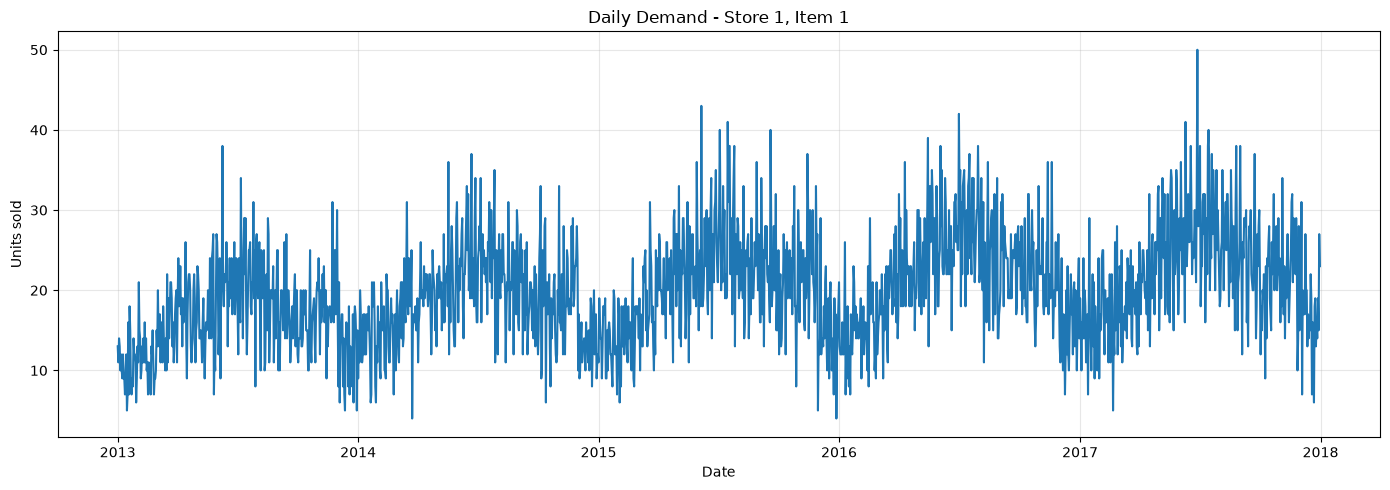

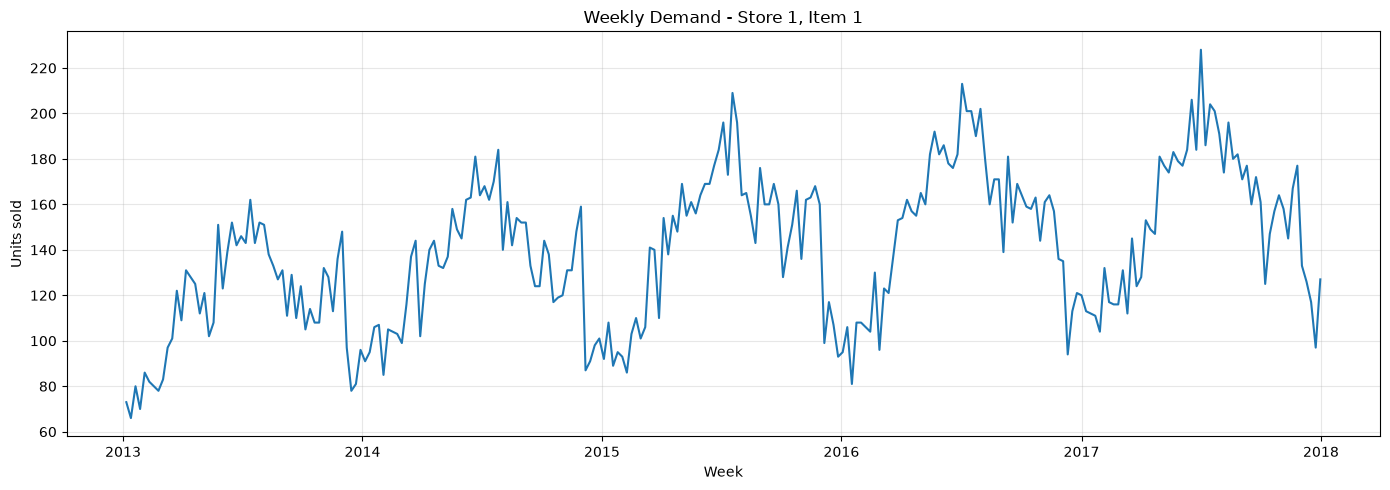

In [4]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title(f"Daily Demand - Store {STORE_ID}, Item {ITEM_ID}")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

weekly_sales = daily_sales.resample("W").sum()
plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)
plt.title(f"Weekly Demand - Store {STORE_ID}, Item {ITEM_ID}")
plt.xlabel("Week")
plt.ylabel("Units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:
sales_values = daily_sales.to_numpy(dtype=np.float32)
number_of_observations = len(sales_values)

if number_of_observations <= LOOK_BACK + 20:
    raise ValueError("The selected time series is too short for the configured look-back window.")

train_end = int(number_of_observations * 0.70)
validation_end = int(number_of_observations * 0.85)

train_values = sales_values[:train_end]
scale_min = float(train_values.min())
scale_max = float(train_values.max())
scale_range = scale_max - scale_min

if scale_range == 0:
    scale_range = 1.0

scaled_sales = (sales_values - scale_min) / scale_range


def create_windows(values, first_target, last_target, look_back):
    x_values = []
    y_values = []
    for target_index in range(first_target, last_target):
        x_values.append(values[target_index - look_back:target_index])
        y_values.append(values[target_index])
    return (
        np.asarray(x_values, dtype=np.float32).reshape(-1, look_back, 1),
        np.asarray(y_values, dtype=np.float32).reshape(-1, 1)
    )


x_train, y_train = create_windows(scaled_sales, LOOK_BACK, train_end, LOOK_BACK)
x_validation, y_validation = create_windows(scaled_sales, train_end, validation_end, LOOK_BACK)
x_test, y_test = create_windows(scaled_sales, validation_end, number_of_observations, LOOK_BACK)

test_dates = daily_sales.index[validation_end:]

print("Training windows:", x_train.shape, y_train.shape)
print("Validation windows:", x_validation.shape, y_validation.shape)
print("Testing windows:", x_test.shape, y_test.shape)
print("Train end:", daily_sales.index[train_end - 1].date())
print("Validation end:", daily_sales.index[validation_end - 1].date())
print("Test start:", daily_sales.index[validation_end].date())


Training windows: (1248, 30, 1) (1248, 1)
Validation windows: (274, 30, 1) (274, 1)
Testing windows: (274, 30, 1) (274, 1)
Train end: 2016-07-01
Validation end: 2017-04-01
Test start: 2017-04-02


In [6]:
train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_dataset = train_dataset.shuffle(len(x_train), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
validation_dataset = tf.data.Dataset.from_tensor_slices((x_validation, y_validation)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(LOOK_BACK, 1)),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )
]

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 83ms/step - loss: 0.0318 - mae: 0.1369 - val_loss: 0.0220 - val_mae: 0.1179 - learning_rate: 0.0010
Epoch 2/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0191 - mae: 0.1080 - val_loss: 0.0198 - val_mae: 0.1141 - learning_rate: 0.0010
Epoch 3/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0187 - mae: 0.1070 - val_loss: 0.0191 - val_mae: 0.1130 - learning_rate: 0.0010
Epoch 4/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0184 - mae: 0.1059 - val_loss: 0.0191 - val_mae: 0.1129 - learning_rate: 0.0010
Epoch 5/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0184 - mae: 0.1064 - val_loss: 0.0194 - val_mae: 0.1131 - learning_rate: 0.0010
Epoch 6/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0188 - mae: 0.1075 - val_loss: 0.0196 - val_mae: 0.1150 - learning_rate: 0.0010
Epoch 7/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0183 - mae: 0.1058 - val_loss: 0.0203 - val_mae: 0.1172 - learning_rate: 5.0000e-04
Epoch 8/25
39/39 ━━

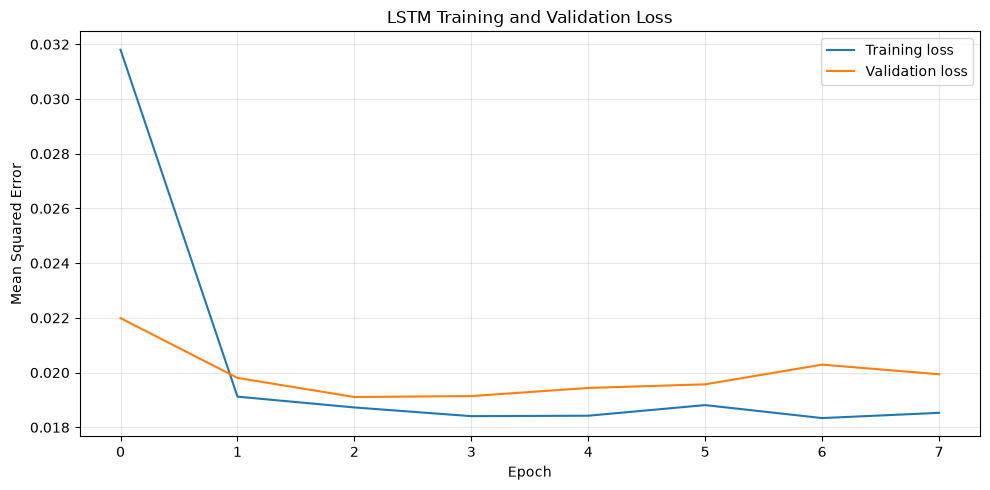

In [7]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "training_loss.png", dpi=150)
plt.show()


Test MAE: 4.864
Test RMSE: 6.190
Test MAPE: 22.75%


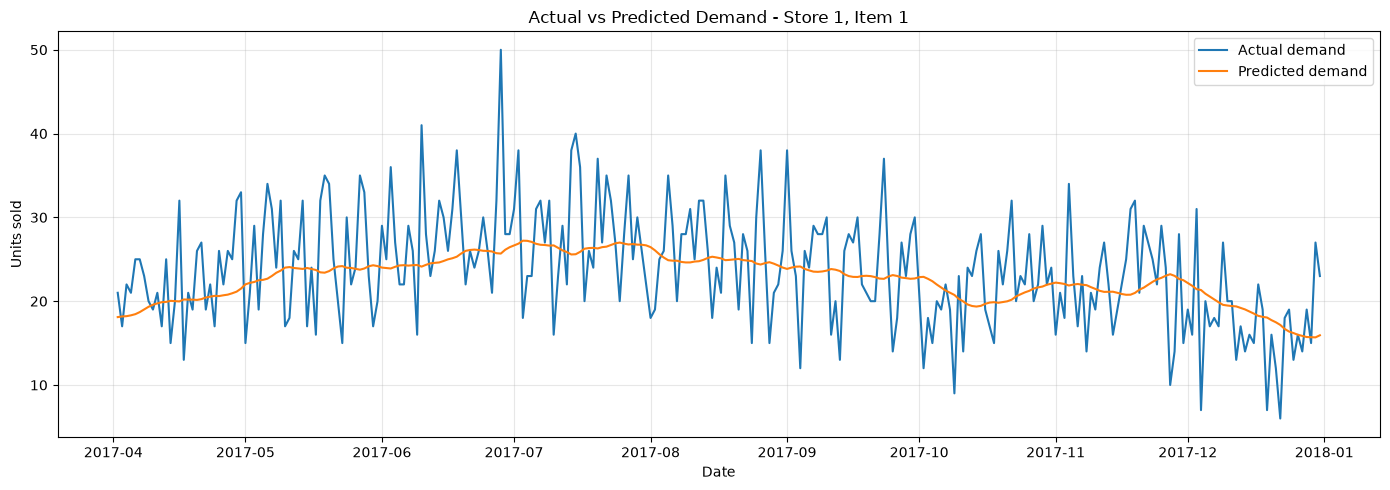

In [8]:
test_predictions_scaled = model.predict(test_dataset, verbose=0).reshape(-1)
y_test_scaled = y_test.reshape(-1)

test_predictions = test_predictions_scaled * scale_range + scale_min
y_test_actual = y_test_scaled * scale_range + scale_min

test_predictions = np.maximum(test_predictions, 0)
absolute_errors = np.abs(y_test_actual - test_predictions)
mae = float(np.mean(absolute_errors))
rmse = float(np.sqrt(np.mean((y_test_actual - test_predictions) ** 2)))

non_zero_actual = y_test_actual != 0
if np.any(non_zero_actual):
    mape = float(np.mean(
        np.abs((y_test_actual[non_zero_actual] - test_predictions[non_zero_actual]) /
               y_test_actual[non_zero_actual])
    ) * 100)
else:
    mape = float("nan")

print(f"Test MAE: {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test MAPE: {mape:.2f}%" if np.isfinite(mape) else "Test MAPE: not defined because all actual values are zero")

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_test_actual, label="Actual demand")
plt.plot(test_dates, test_predictions, label="Predicted demand")
plt.title(f"Actual vs Predicted Demand - Store {STORE_ID}, Item {ITEM_ID}")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "actual_vs_predicted.png", dpi=150)
plt.show()

prediction_results = pd.DataFrame({
    "date": test_dates,
    "store": STORE_ID,
    "item": ITEM_ID,
    "actual_sales": y_test_actual,
    "predicted_sales": test_predictions
})
prediction_results.to_csv(REPORT_DIR / "test_predictions.csv", index=False)


In [9]:
MODEL_PATH = MODEL_DIR / "retailmind_lstm_demand.keras"
METADATA_PATH = MODEL_DIR / "retailmind_lstm_metadata.json"
METRICS_PATH = REPORT_DIR / "metrics.json"

model.save(MODEL_PATH)

metadata = {
    "store_id": STORE_ID,
    "item_id": ITEM_ID,
    "look_back": LOOK_BACK,
    "scale_min": scale_min,
    "scale_max": scale_max,
    "last_date": str(daily_sales.index[-1].date()),
    "last_window_scaled": scaled_sales[-LOOK_BACK:].astype(float).tolist(),
    "dataset": "Store Item Demand Forecasting Challenge",
    "target_column": "sales"
}

with METADATA_PATH.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

metrics = {
    "store_id": STORE_ID,
    "item_id": ITEM_ID,
    "look_back": LOOK_BACK,
    "mae": mae,
    "rmse": rmse,
    "mape": mape if np.isfinite(mape) else None,
    "test_observations": int(len(y_test_actual))
}

with METRICS_PATH.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print("Saved metrics:", METRICS_PATH)


Saved model: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\forecasting\retailmind_lstm_demand.keras
Saved metadata: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\forecasting\retailmind_lstm_metadata.json
Saved metrics: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day9_demand_forecast\metrics.json


In [10]:
module_source = 'from pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport tensorflow as tf\n\n\ndef _find_project_dir():\n    current_dir = Path.cwd().resolve()\n    return next(\n        (folder for folder in [current_dir, *current_dir.parents]\n         if (folder / "models" / "forecasting").is_dir()),\n        current_dir.parent if current_dir.name == "src" else current_dir\n    )\n\n\ndef forecast_demand(steps=14, project_dir=None, save_csv=True):\n    if steps < 1:\n        raise ValueError("steps must be at least 1")\n\n    root = Path(project_dir).resolve() if project_dir else _find_project_dir()\n    model_dir = root / "models" / "forecasting"\n    model_path = model_dir / "retailmind_lstm_demand.keras"\n    metadata_path = model_dir / "retailmind_lstm_metadata.json"\n\n    if not model_path.is_file():\n        raise FileNotFoundError(f"Trained demand model not found: {model_path}")\n    if not metadata_path.is_file():\n        raise FileNotFoundError(f"Demand model metadata not found: {metadata_path}")\n\n    with metadata_path.open("r", encoding="utf-8") as file:\n        metadata = json.load(file)\n\n    model = tf.keras.models.load_model(model_path, compile=False)\n    window = np.asarray(metadata["last_window_scaled"], dtype=np.float32).reshape(1, -1, 1)\n    scale_min = float(metadata["scale_min"])\n    scale_max = float(metadata["scale_max"])\n    scale_range = scale_max - scale_min\n    if scale_range == 0:\n        scale_range = 1.0\n\n    predictions = []\n    for _ in range(steps):\n        next_scaled = float(model.predict(window, verbose=0)[0, 0])\n        next_sales = max(0.0, next_scaled * scale_range + scale_min)\n        predictions.append(next_sales)\n        next_scaled = (next_sales - scale_min) / scale_range\n        window = np.concatenate(\n            [window[:, 1:, :], np.asarray([[[next_scaled]]], dtype=np.float32)],\n            axis=1\n        )\n\n    start_date = pd.Timestamp(metadata["last_date"]) + pd.Timedelta(days=1)\n    forecast_dates = pd.date_range(start=start_date, periods=steps, freq="D")\n    result = pd.DataFrame({\n        "date": forecast_dates,\n        "store": metadata["store_id"],\n        "item": metadata["item_id"],\n        "forecast_sales": predictions\n    })\n\n    if save_csv:\n        report_dir = root / "reports" / "day9_demand_forecast"\n        report_dir.mkdir(parents=True, exist_ok=True)\n        result.to_csv(report_dir / "future_demand_forecast.csv", index=False)\n\n    return result\n'

MODULE_PATH = SRC_DIR / "demand_forecaster.py"
MODULE_PATH.write_text(module_source, encoding="utf-8")
print("Reusable forecasting module created:", MODULE_PATH)


Reusable forecasting module created: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\src\demand_forecaster.py


In [11]:
import importlib
import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import demand_forecaster
importlib.reload(demand_forecaster)

future_forecast = demand_forecaster.forecast_demand(
    steps=14,
    project_dir=PROJECT_DIR,
    save_csv=True
)

print(future_forecast.to_string(index=False))
print("Future forecast saved to:", REPORT_DIR / "future_demand_forecast.csv")


      date  store  item  forecast_sales
2018-01-01      1     1       16.275503
2018-01-02      1     1       16.542144
2018-01-03      1     1       16.746604
2018-01-04      1     1       16.921825
2018-01-05      1     1       17.052584
2018-01-06      1     1       17.156381
2018-01-07      1     1       17.235983
2018-01-08      1     1       17.297220
2018-01-09      1     1       17.338796
2018-01-10      1     1       17.373867
2018-01-11      1     1       17.400013
2018-01-12      1     1       17.422456
2018-01-13      1     1       17.436847
2018-01-14      1     1       17.448754
Future forecast saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day9_demand_forecast\future_demand_forecast.csv
